# Estudo de Qualidade do Modelo de Machine Learning — Nuclea MFS
## Motor ForeSig: Avaliação do Modelo de Risco de Crédito (FIDC)

---

**Autor:** Diego Degan  
**Data:** Maio / 2026  
**Versão:** 1.0  
**Modelo em Avaliação:** `RandomForestClassifier` (Probabilidade de Default — PD) + `RandomForestRegressor` (Previsão de Atraso)

---

### Objetivo

Este estudo tem como objetivo avaliar a qualidade e a robustez dos modelos de machine learning que compõem o **Motor ForeSig (MFS)** — motor híbrido de risco de crédito para seleção de boletos em um FIDC. A análise cobre:

1. **Análise Exploratória** dos dados de modelagem  
2. **Avaliação de Performance** com métricas canônicas da indústria de crédito (AUC-ROC, KS, Gini, Calibração)  
3. **Análise de Estabilidade Populacional (PSI)** para monitoramento de drift  
4. **Explicabilidade (SHAP)** — importância das features  
5. **Backtest Cronológico** (out-of-time) — validação temporal rigorosa  
6. **Análise de Sobrevivência** (Kaplan-Meier) para recebíveis  
7. **Impacto Financeiro** projetado do motor de decisão  

### Estrutura das Features

O modelo integra 4 camadas de informação:  
- **Cadastral/Operacional**: `vlr_nominal`, `cd_cnae_prin`  
- **Comportamental**: `media_atraso_dias`, `sacado_indice_liquidez_1m`, `score_materialidade_v2`  
- **Graph Analytics** (NetworkX/Neo4j): `pagador_pagerank`, `beneficiario_degree`, `total_exposed_value`, `avg_payer_risk`  
- **Macroeconômico** (BACEN API): `taxa_selic_emissao`, `diff_selic_30d`

---
## 0. Setup e Configuração do Ambiente

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
import os
import joblib

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report,
    mean_squared_error, mean_absolute_error,
    brier_score_loss
)
from sklearn.calibration import calibration_curve
from scipy.stats import ks_2samp

warnings.filterwarnings('ignore')

# Estilo visual padronizado para pesquisa
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
FIGSIZE_DEFAULT = (12, 5)
COLOR_POS = '#e74c3c'   # Classe positiva (default)
COLOR_NEG = '#2ecc71'   # Classe negativa (adimplente)
COLOR_MODEL = '#3498db' # Curvas do modelo

# Caminhos — relativos à raiz do repositório
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_PATH = os.path.join(BASE_DIR, 'data', 'processed', 'base_modelagem.csv')
MODELS_DIR = os.path.join(BASE_DIR, 'backend', 'models')

print(f"Base de dados: {DATA_PATH}")
print(f"Diretório de modelos: {MODELS_DIR}")
print(f"Arquivo existe: {os.path.exists(DATA_PATH)}")

Base de dados: C:\Users\Degan\Documents\Antigravity\Nuclea\data\processed\base_modelagem.csv
Diretório de modelos: C:\Users\Degan\Documents\Antigravity\Nuclea\backend\models
Arquivo existe: True


---
## 1. Análise Exploratória dos Dados (EDA)

In [2]:
df = pd.read_csv(DATA_PATH)
df['dt_emissao'] = pd.to_datetime(df['dt_emissao'])

print("=" * 55)
print(f"  VISÃO GERAL DA BASE DE MODELAGEM")
print("=" * 55)
print(f"  Registros (boletos):  {len(df):,}")
print(f"  Features:             {df.shape[1]}")
print(f"  Período:              {df['dt_emissao'].min().date()} → {df['dt_emissao'].max().date()}")
print(f"  Volume total (R$):    {df['vlr_nominal'].sum():,.2f}")
print(f"  Ticket médio (R$):    {df['vlr_nominal'].mean():,.2f}")
print(f"  Taxa de Default:      {df['default'].mean():.2%}")
print("=" * 55)

  VISÃO GERAL DA BASE DE MODELAGEM
  Registros (boletos):  7,118
  Features:             27
  Período:              2019-08-16 → 2024-05-31
  Volume total (R$):    165,853,488.09
  Ticket médio (R$):    23,300.57
  Taxa de Default:      6.07%


In [3]:
# --- 1.1 Análise de Valores Ausentes ---
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Ausentes': missing, '% Ausência': missing_pct})
missing_df = missing_df[missing_df['Ausentes'] > 0].sort_values('Ausentes', ascending=False)

if missing_df.empty:
    print("✅ Nenhum valor ausente detectado na base de modelagem.")
else:
    print(missing_df.to_string())

✅ Nenhum valor ausente detectado na base de modelagem.


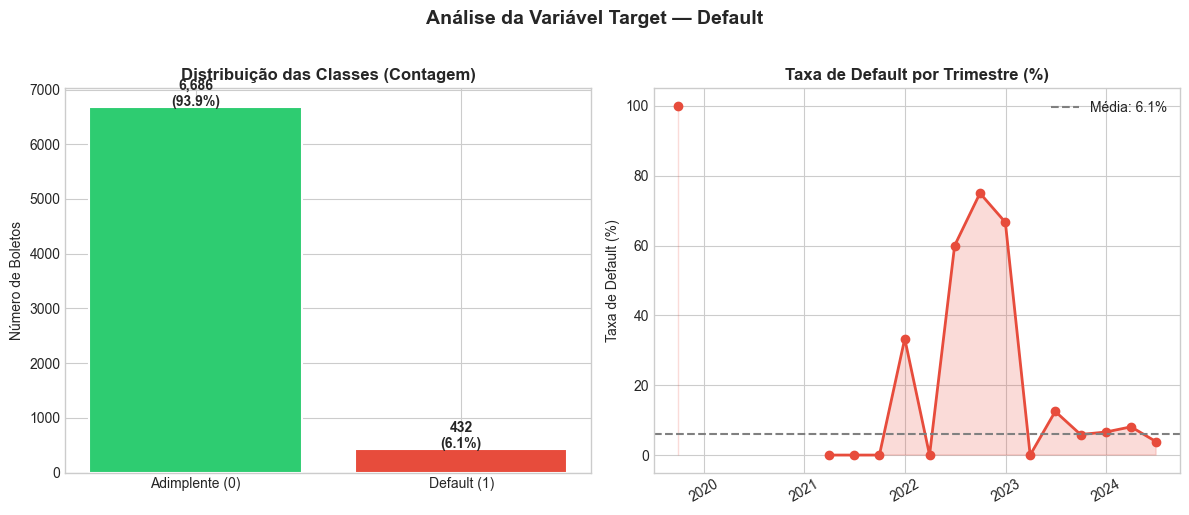


⚠️  DESBALANCEAMENTO: Razão negativo/positivo = 15.5:1
   → O modelo usa class_weight='balanced' para compensar.


In [4]:
# --- 1.2 Distribuição da Variável Target (Default) ---
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_DEFAULT)

# Contagem de classes
counts = df['default'].value_counts()
labels = ['Adimplente (0)', 'Default (1)']
colors = [COLOR_NEG, COLOR_POS]
axes[0].bar(labels, counts.values, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Distribuição das Classes (Contagem)', fontweight='bold')
axes[0].set_ylabel('Número de Boletos')
for bar, val in zip(axes[0].patches, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{val:,}\n({val/len(df):.1%})', ha='center', fontsize=10, fontweight='bold')

# Evolução temporal do default
df_temporal = df.set_index('dt_emissao').resample('Q')['default'].mean() * 100
axes[1].plot(df_temporal.index, df_temporal.values, color=COLOR_POS, marker='o', linewidth=2)
axes[1].fill_between(df_temporal.index, df_temporal.values, alpha=0.2, color=COLOR_POS)
axes[1].axhline(y=df['default'].mean()*100, color='gray', linestyle='--', label=f'Média: {df["default"].mean():.1%}')
axes[1].set_title('Taxa de Default por Trimestre (%)', fontweight='bold')
axes[1].set_ylabel('Taxa de Default (%)')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('Análise da Variável Target — Default', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\n⚠️  DESBALANCEAMENTO: Razão negativo/positivo = {counts[0]/counts[1]:.1f}:1")
print(f"   → O modelo usa class_weight='balanced' para compensar.")

In [5]:
# --- 1.3 Estatísticas Descritivas das Features de Modelagem ---
COLUNAS_EXCLUIR = ['id_boleto', 'id_pagador', 'id_beneficiario', 'dt_emissao', 'default', 'pagou']
features_num = [c for c in df.columns if c not in COLUNAS_EXCLUIR]

desc = df[features_num].describe().T.round(4)
print(desc.to_string())

                                     count          mean           std       min           25%           50%           75%           max
vlr_nominal                         7118.0  2.330057e+04  8.346024e+04    5.2400  4.649600e+02  1.666630e+03  9.436202e+03  3.294630e+06
vlr_baixa                           7118.0  1.820105e+04  5.851069e+04    0.0000  3.171725e+02  1.194330e+03  6.424363e+03  1.019819e+06
dias_atraso                         7118.0  4.864400e+00  2.711670e+01 -116.0000  0.000000e+00  0.000000e+00  1.000000e+00  2.220000e+02
cd_cnae_prin                        7118.0  4.048511e+06  1.412748e+06    0.0000  2.823200e+06  4.663000e+06  4.771701e+06  9.609208e+06
sacado_indice_liquidez_1m           7118.0  7.789000e-01  2.633000e-01    0.0000  6.533000e-01  9.041000e-01  9.716000e-01  1.000000e+00
cedente_indice_liquidez_1m          7118.0  4.638000e-01  4.230000e-01    0.0000  0.000000e+00  5.794000e-01  9.126000e-01  1.000000e+00
score_materialidade_evolucao        7118.

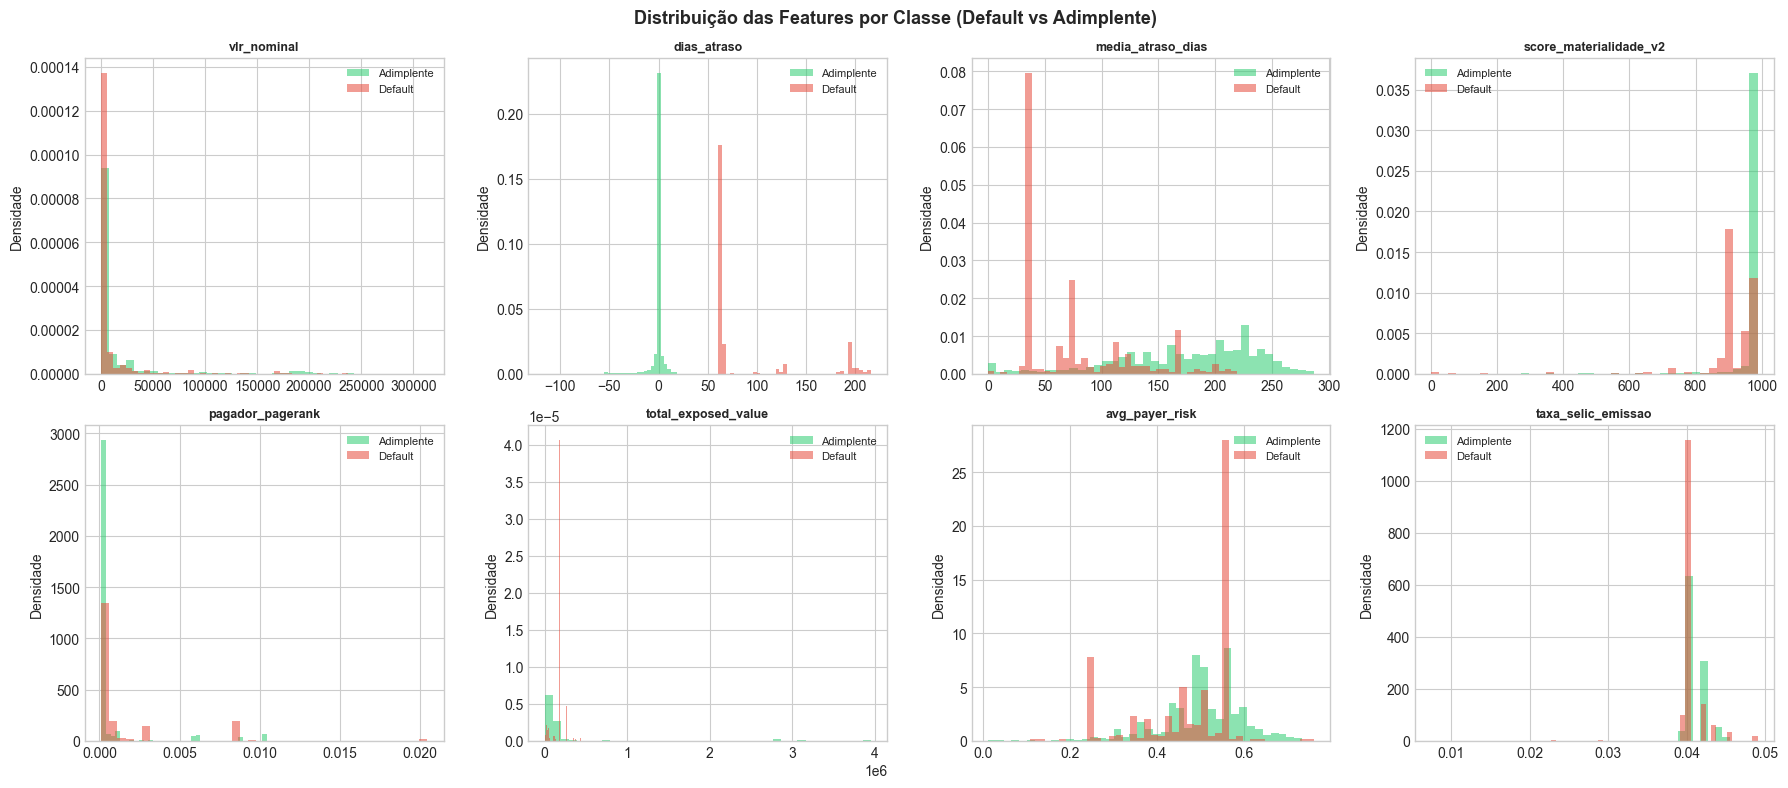

In [6]:
# --- 1.4 Distribuição das Features por Classe de Risco ---
features_plot = [
    'vlr_nominal', 'dias_atraso', 'media_atraso_dias',
    'score_materialidade_v2', 'pagador_pagerank', 'total_exposed_value',
    'avg_payer_risk', 'taxa_selic_emissao'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, feat in enumerate(features_plot):
    if feat not in df.columns:
        continue
    for classe, cor, label in [(0, COLOR_NEG, 'Adimplente'), (1, COLOR_POS, 'Default')]:
        data = df[df['default'] == classe][feat].dropna()
        data = data[data < data.quantile(0.99)]  # remove outliers extremos para visualização
        axes[i].hist(data, bins=40, alpha=0.55, color=cor, label=label, density=True)
    axes[i].set_title(feat, fontsize=9, fontweight='bold')
    axes[i].set_ylabel('Densidade')
    axes[i].legend(fontsize=8)

plt.suptitle('Distribuição das Features por Classe (Default vs Adimplente)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

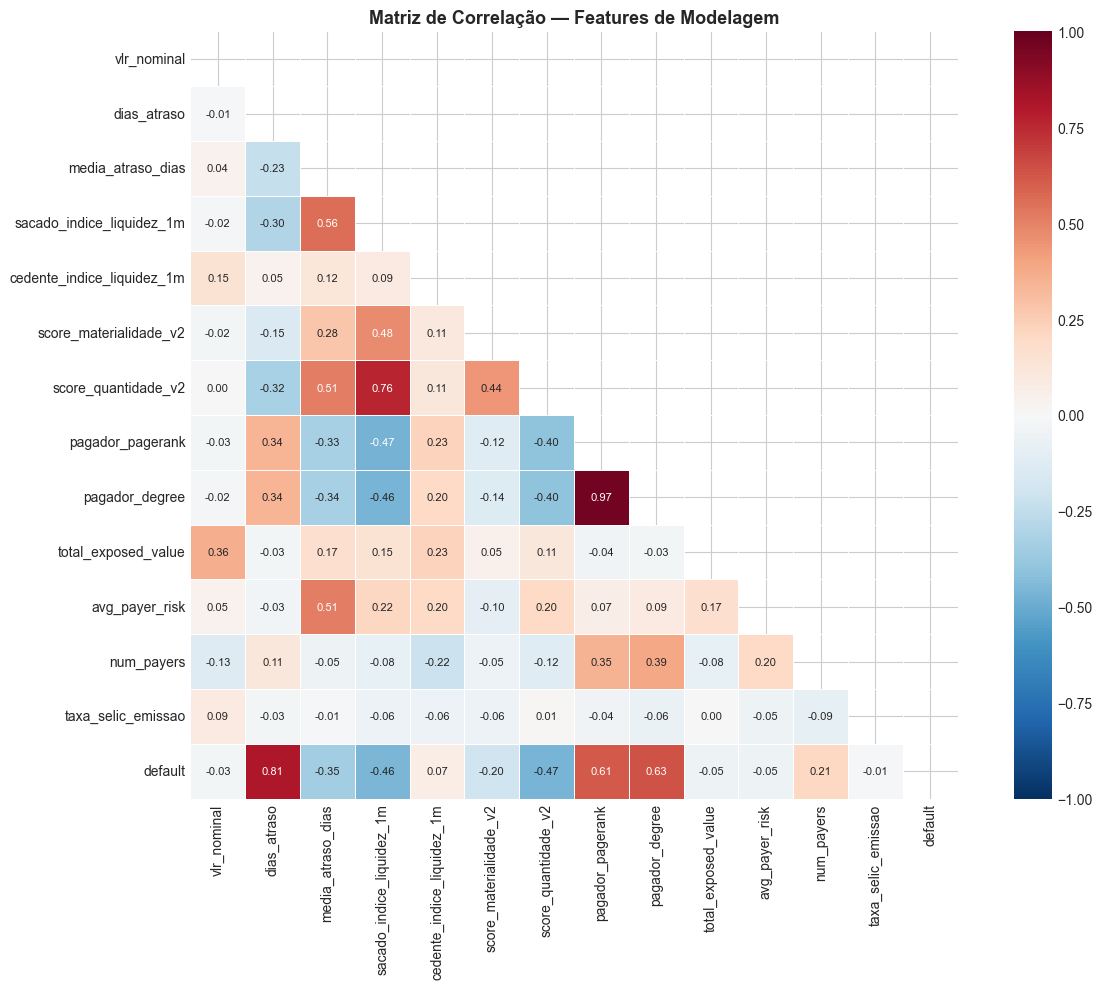


Top 10 Features por Correlação (|ρ|) com Default:
                            |Correlação|
dias_atraso                     0.808528
pagador_degree                  0.633358
pagador_pagerank                0.609761
score_quantidade_v2             0.467882
sacado_indice_liquidez_1m       0.456092
media_atraso_dias               0.348272
num_payers                      0.209944
score_materialidade_v2          0.195465
cedente_indice_liquidez_1m      0.073622
avg_payer_risk                  0.049942


In [7]:
# --- 1.5 Matriz de Correlação das Features ---
corr_features = [
    'vlr_nominal', 'dias_atraso', 'media_atraso_dias',
    'sacado_indice_liquidez_1m', 'cedente_indice_liquidez_1m',
    'score_materialidade_v2', 'score_quantidade_v2',
    'pagador_pagerank', 'pagador_degree',
    'total_exposed_value', 'avg_payer_risk', 'num_payers',
    'taxa_selic_emissao', 'default'
]
corr_features = [c for c in corr_features if c in df.columns]

corr_matrix = df[corr_features].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
    center=0, vmin=-1, vmax=1, square=True, ax=ax,
    linewidths=0.5, annot_kws={'size': 8}
)
ax.set_title('Matriz de Correlação — Features de Modelagem', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Top correlações com target
corr_with_target = corr_matrix['default'].drop('default').abs().sort_values(ascending=False)
print("\nTop 10 Features por Correlação (|ρ|) com Default:")
print(corr_with_target.head(10).to_frame('|Correlação|').to_string())

---
## 2. Preparação dos Dados e Pipeline de Treinamento

In [8]:
# --- 2.1 Definição de Features e Target ---
REMOVER = [
    'default', 'dias_atraso', 'id_boleto', 'id_pagador', 'id_beneficiario',
    'dt_emissao', 'pagou', 'vlr_baixa'
]
features = [c for c in df.columns if c not in REMOVER]

# Verificar features de grafos e macro (obrigatórias no MFS)
macro_graph_kw = ['pagerank', 'centrality', 'degree', 'selic', 'taxa']
encontradas = [f for f in features if any(k in f.lower() for k in macro_graph_kw)]
print(f"Features obrigatórias (grafo + macro) detectadas: {encontradas}")
print(f"Total de features para modelagem: {len(features)}")
print("\nFeatures selecionadas:", features)

df_model = df[features + ['default', 'dias_atraso']].dropna()

# Normalizar colunas financeiras e de taxa (conforme model_trainer.py)
scaler = StandardScaler()
cols_to_scale = [col for col in features if 'valor' in col.lower() or 'taxa' in col.lower() or 'vlr' in col.lower()]
print(f"\nColunas normalizadas com StandardScaler: {cols_to_scale}")
df_model = df_model.copy()
if cols_to_scale:
    df_model[cols_to_scale] = scaler.fit_transform(df_model[cols_to_scale])

X = df_model[features]
y_pd = df_model['default']
y_delay = df_model['dias_atraso']

print(f"\nShape final de X: {X.shape}")
print(f"Distribuição do target: {y_pd.value_counts().to_dict()}")

Features obrigatórias (grafo + macro) detectadas: ['pagador_pagerank', 'pagador_degree', 'beneficiario_pagerank', 'beneficiario_degree', 'taxa_selic_emissao', 'diff_selic_30d']
Total de features para modelagem: 19

Features selecionadas: ['vlr_nominal', 'cd_cnae_prin', 'sacado_indice_liquidez_1m', 'cedente_indice_liquidez_1m', 'score_materialidade_evolucao', 'media_atraso_dias', 'indicador_liquidez_quantitativo_3m', 'share_vl_inad_pag_bol_6_a_15d', 'score_quantidade_v2', 'score_materialidade_v2', 'pagador_pagerank', 'pagador_degree', 'beneficiario_pagerank', 'beneficiario_degree', 'total_exposed_value', 'avg_payer_risk', 'num_payers', 'taxa_selic_emissao', 'diff_selic_30d']

Colunas normalizadas com StandardScaler: ['vlr_nominal', 'taxa_selic_emissao']

Shape final de X: (7118, 19)
Distribuição do target: {0: 6686, 1: 432}


In [9]:
# --- 2.2 Split Treino / Teste (Hold-out Aleatório — Replicando model_trainer.py) ---
X_train, X_test, y_train, y_test, y_delay_train, y_delay_test = train_test_split(
    X, y_pd, y_delay, test_size=0.2, random_state=42, stratify=y_pd
)

print("Split Aleatório Estratificado (80/20):")
print(f"  Treino: {len(X_train):,} amostras | Default: {y_train.mean():.2%}")
print(f"  Teste:  {len(X_test):,} amostras  | Default: {y_test.mean():.2%}")

Split Aleatório Estratificado (80/20):
  Treino: 5,694 amostras | Default: 6.08%
  Teste:  1,424 amostras  | Default: 6.04%


In [10]:
# --- 2.3 Treinamento dos Modelos ---
pd_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
delay_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Treinando RandomForestClassifier (PD)...")
pd_model.fit(X_train, y_train)
print("Treinando RandomForestRegressor (Delay)...")
delay_model.fit(X_train, y_delay_train)
print("✅ Treinamento concluído.")

# Predições
y_prob = pd_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob > 0.5).astype(int)
delay_preds = delay_model.predict(X_test)

Treinando RandomForestClassifier (PD)...


Treinando RandomForestRegressor (Delay)...


✅ Treinamento concluído.


---
## 3. Avaliação de Performance — Métricas Canônicas de Crédito

> **Referências de mercado** para modelos de risco de crédito em FIDCs:
> - **AUC-ROC** ≥ 0.70: modelo com poder discriminatório aceitável  
> - **KS** ≥ 0.30: modelo com boa separação entre bons e maus pagadores  
> - **Gini** = 2 × AUC − 1 (derivado do AUC-ROC)  
> - **PSI** < 0.10: população estável; < 0.25: alerta; ≥ 0.25: retreino necessário  
> - **Brier Score** < 0.25: calibração aceitável

In [11]:
# --- 3.1 Métricas Resumo ---
auc_roc = roc_auc_score(y_test, y_prob)
gini = 2 * auc_roc - 1
brier = brier_score_loss(y_test, y_prob)
avg_precision = average_precision_score(y_test, y_prob)

# KS
pos_preds = y_prob[y_test == 1]
neg_preds = y_prob[y_test == 0]
ks_stat, ks_pval = ks_2samp(pos_preds, neg_preds)

# RMSE do regressor de atraso
rmse_delay = np.sqrt(mean_squared_error(y_delay_test, delay_preds))
mae_delay = mean_absolute_error(y_delay_test, delay_preds)

# Calibração
expected_rate = float(y_prob.mean())
observed_rate = float(y_test.mean())
calibration_ratio = expected_rate / observed_rate if observed_rate > 0 else np.nan

print("\n" + "="*55)
print("  PAINEL DE MÉTRICAS — MODELO PD (CLASSIFICADOR)")
print("="*55)
print(f"  AUC-ROC:              {auc_roc:.4f}   {'✅' if auc_roc >= 0.70 else '⚠️'}")
print(f"  Gini:                 {gini:.4f}   {'✅' if gini >= 0.40 else '⚠️'}")
print(f"  KS Statistic:         {ks_stat:.4f}   {'✅' if ks_stat >= 0.30 else '⚠️'} (p-val: {ks_pval:.2e})")
print(f"  Brier Score:          {brier:.4f}   {'✅' if brier < 0.25 else '⚠️'} (menor = melhor)")
print(f"  Avg Precision (AP):   {avg_precision:.4f}")
print(f"  Calibração (Esp/Obs): {expected_rate:.4f} / {observed_rate:.4f} → Razão: {calibration_ratio:.3f}")
print("="*55)
print("  PAINEL DE MÉTRICAS — MODELO DELAY (REGRESSÃO)")
print("="*55)
print(f"  RMSE (dias):          {rmse_delay:.2f}")
print(f"  MAE  (dias):          {mae_delay:.2f}")
print("="*55)


  PAINEL DE MÉTRICAS — MODELO PD (CLASSIFICADOR)
  AUC-ROC:              0.9135   ✅
  Gini:                 0.8270   ✅
  KS Statistic:         0.7758   ✅ (p-val: 5.80e-51)
  Brier Score:          0.0233   ✅ (menor = melhor)
  Avg Precision (AP):   0.7723
  Calibração (Esp/Obs): 0.0546 / 0.0604 → Razão: 0.904
  PAINEL DE MÉTRICAS — MODELO DELAY (REGRESSÃO)
  RMSE (dias):          22.65
  MAE  (dias):          6.83


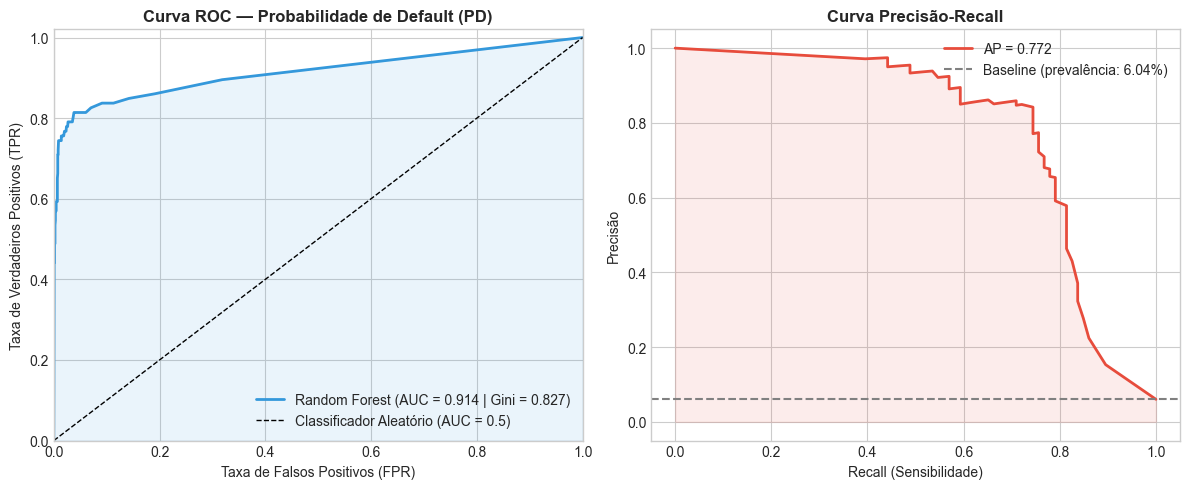

In [12]:
# --- 3.2 Curva ROC e Curva Precisão-Recall ---
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_DEFAULT)

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, color=COLOR_MODEL, lw=2, label=f'Random Forest (AUC = {auc_roc:.3f} | Gini = {gini:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Classificador Aleatório (AUC = 0.5)')
axes[0].fill_between(fpr, tpr, alpha=0.1, color=COLOR_MODEL)
axes[0].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
axes[0].set_title('Curva ROC — Probabilidade de Default (PD)', fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1.02])

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_prob)
axes[1].plot(recall, precision, color=COLOR_POS, lw=2, label=f'AP = {avg_precision:.3f}')
axes[1].axhline(y=y_test.mean(), color='gray', linestyle='--', label=f'Baseline (prevalência: {y_test.mean():.2%})')
axes[1].fill_between(recall, precision, alpha=0.1, color=COLOR_POS)
axes[1].set_xlabel('Recall (Sensibilidade)')
axes[1].set_ylabel('Precisão')
axes[1].set_title('Curva Precisão-Recall', fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

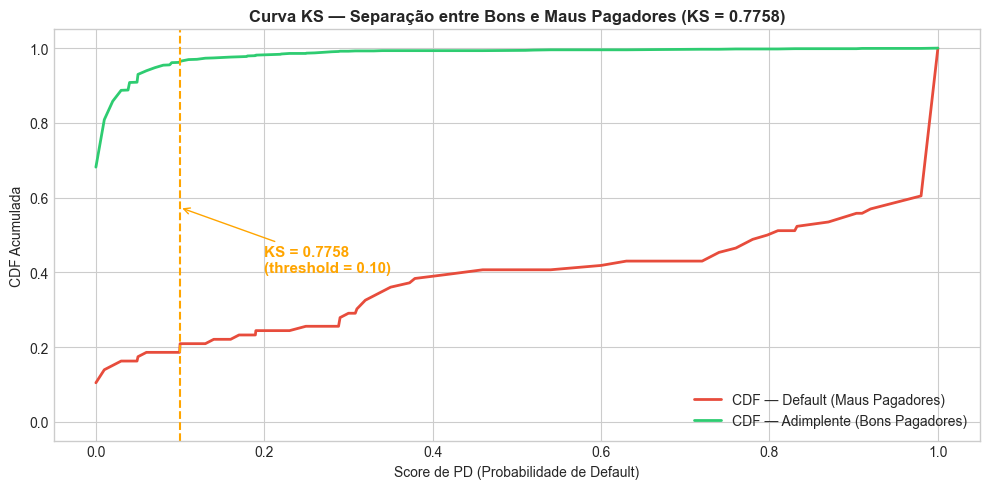


Interpretação do KS:
  KS = 0.7758 → EXCELENTE — modelo com altíssimo poder de separação


In [13]:
# --- 3.3 Curva KS (Kolmogorov-Smirnov) ---
fig, ax = plt.subplots(figsize=(10, 5))

scores_sorted = np.sort(np.unique(y_prob))
cdf_pos = [np.mean(pos_preds <= t) for t in scores_sorted]
cdf_neg = [np.mean(neg_preds <= t) for t in scores_sorted]
diff = np.abs(np.array(cdf_pos) - np.array(cdf_neg))
ks_threshold = scores_sorted[np.argmax(diff)]

ax.plot(scores_sorted, cdf_pos, color=COLOR_POS, lw=2, label='CDF — Default (Maus Pagadores)')
ax.plot(scores_sorted, cdf_neg, color=COLOR_NEG, lw=2, label='CDF — Adimplente (Bons Pagadores)')
ax.axvline(x=ks_threshold, color='orange', linestyle='--', lw=1.5)
ax.fill_betweenx([0, 1], ks_threshold, ks_threshold, alpha=0)

# Seta indicando o ponto de KS máximo
ks_y_pos = np.mean(pos_preds <= ks_threshold)
ks_y_neg = np.mean(neg_preds <= ks_threshold)
ax.annotate(
    f'KS = {ks_stat:.4f}\n(threshold = {ks_threshold:.2f})',
    xy=(ks_threshold, (ks_y_pos + ks_y_neg) / 2),
    xytext=(ks_threshold + 0.1, 0.4),
    arrowprops=dict(arrowstyle='->', color='orange'),
    fontsize=11, color='orange', fontweight='bold'
)

ax.set_xlabel('Score de PD (Probabilidade de Default)')
ax.set_ylabel('CDF Acumulada')
ax.set_title(f'Curva KS — Separação entre Bons e Maus Pagadores (KS = {ks_stat:.4f})', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# Interpretação
print(f"\nInterpretação do KS:")
if ks_stat >= 0.40: interp = "EXCELENTE — modelo com altíssimo poder de separação"
elif ks_stat >= 0.30: interp = "BOM — poder de separação adequado para operação"
elif ks_stat >= 0.20: interp = "ACEITÁVEL — modelo moderado; revisar features"
else: interp = "FRACO — modelo necessita de revisão urgente"
print(f"  KS = {ks_stat:.4f} → {interp}")

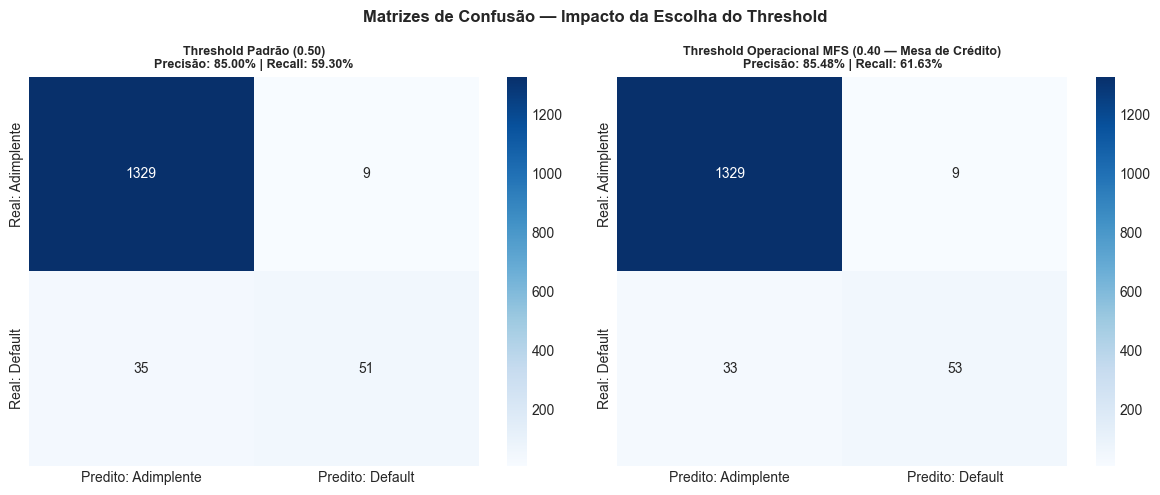


Relatório de Classificação (threshold = 0.5):
              precision    recall  f1-score   support

  Adimplente       0.97      0.99      0.98      1338
     Default       0.85      0.59      0.70        86

    accuracy                           0.97      1424
   macro avg       0.91      0.79      0.84      1424
weighted avg       0.97      0.97      0.97      1424



In [14]:
# --- 3.4 Matriz de Confusão ---
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_DEFAULT)

for ax, thresh, title in [
    (axes[0], 0.5, 'Threshold Padrão (0.50)'),
    (axes[1], 0.40, 'Threshold Operacional MFS (0.40 — Mesa de Crédito)')
]:
    y_pred_t = (y_prob >= thresh).astype(int)
    cm = confusion_matrix(y_test, y_pred_t)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Predito: Adimplente', 'Predito: Default'],
        yticklabels=['Real: Adimplente', 'Real: Default']
    )
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'{title}\nPrecisão: {tp/(tp+fp):.2%} | Recall: {tp/(tp+fn):.2%}', fontsize=9, fontweight='bold')

plt.suptitle('Matrizes de Confusão — Impacto da Escolha do Threshold', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nRelatório de Classificação (threshold = 0.5):")
print(classification_report(y_test, y_pred, target_names=['Adimplente', 'Default']))

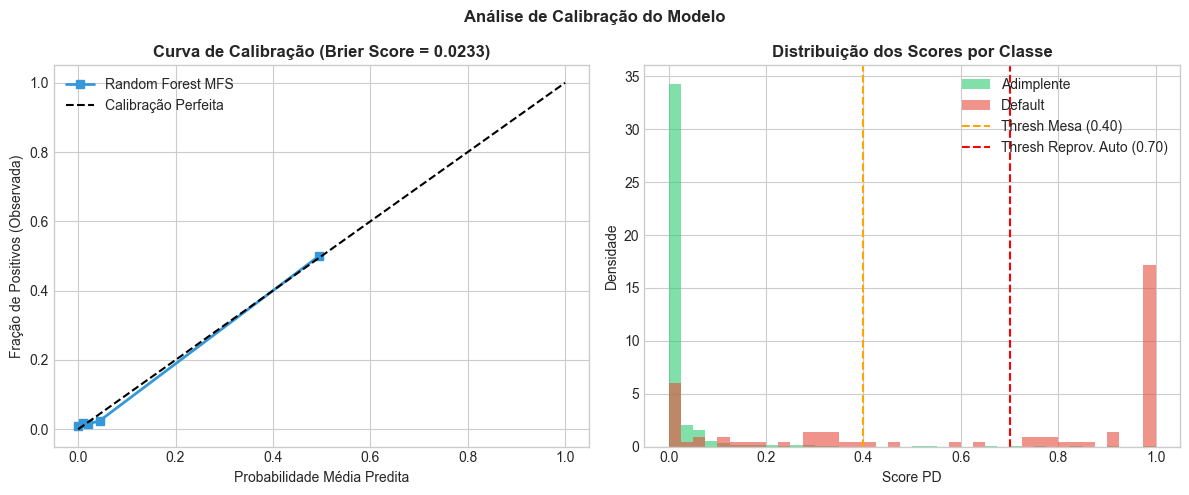


Calibração: Taxa Esperada = 0.0546 | Taxa Observada = 0.0604
Razão Exp/Obs = 0.904  (✅ Bem calibrado)


In [15]:
# --- 3.5 Análise de Calibração ---
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_DEFAULT)

# Curva de Calibração
frac_positivos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy='quantile')
axes[0].plot(mean_pred, frac_positivos, 's-', color=COLOR_MODEL, lw=2, label='Random Forest MFS')
axes[0].plot([0, 1], [0, 1], 'k--', label='Calibração Perfeita')
axes[0].set_xlabel('Probabilidade Média Predita')
axes[0].set_ylabel('Fração de Positivos (Observada)')
axes[0].set_title(f'Curva de Calibração (Brier Score = {brier:.4f})', fontweight='bold')
axes[0].legend()

# Distribuição dos scores por classe
axes[1].hist(neg_preds, bins=40, alpha=0.6, color=COLOR_NEG, label='Adimplente', density=True)
axes[1].hist(pos_preds, bins=40, alpha=0.6, color=COLOR_POS, label='Default', density=True)
axes[1].axvline(x=0.40, color='orange', linestyle='--', lw=1.5, label='Thresh Mesa (0.40)')
axes[1].axvline(x=0.70, color='red', linestyle='--', lw=1.5, label='Thresh Reprov. Auto (0.70)')
axes[1].set_xlabel('Score PD')
axes[1].set_ylabel('Densidade')
axes[1].set_title('Distribuição dos Scores por Classe', fontweight='bold')
axes[1].legend()

plt.suptitle('Análise de Calibração do Modelo', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nCalibração: Taxa Esperada = {expected_rate:.4f} | Taxa Observada = {observed_rate:.4f}")
print(f"Razão Exp/Obs = {calibration_ratio:.3f}  "
      f"({'✅ Bem calibrado' if 0.8 <= calibration_ratio <= 1.2 else '⚠️ Revisar calibração'})")

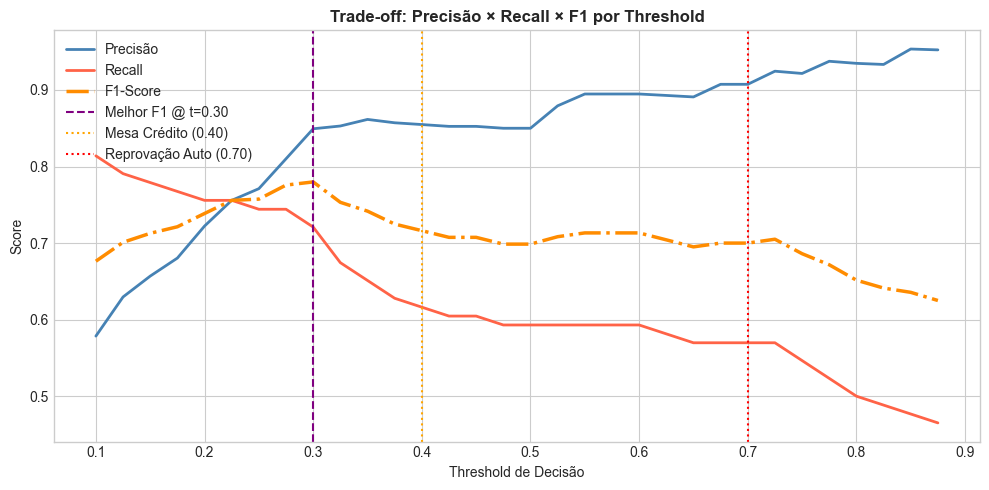


Melhor threshold por F1-Score: 0.30
  Precisão @ 0.30: 0.8493
  Recall   @ 0.30: 0.7209
  F1       @ 0.30: 0.7799


In [16]:
# --- 3.6 Análise de Threshold — Trade-off Precisão × Recall × F1 ---
thresholds = np.arange(0.1, 0.9, 0.025)
precisions, recalls, f1s = [], [], []

for t in thresholds:
    y_t = (y_prob >= t).astype(int)
    tp = ((y_t == 1) & (y_test == 1)).sum()
    fp = ((y_t == 1) & (y_test == 0)).sum()
    fn = ((y_t == 0) & (y_test == 1)).sum()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    precisions.append(prec)
    recalls.append(rec)
    f1s.append(f1)

best_f1_idx = np.argmax(f1s)
best_thresh = thresholds[best_f1_idx]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, precisions, color='steelblue', lw=2, label='Precisão')
ax.plot(thresholds, recalls, color='tomato', lw=2, label='Recall')
ax.plot(thresholds, f1s, color='darkorange', lw=2.5, label='F1-Score', linestyle='-.')
ax.axvline(x=best_thresh, color='purple', linestyle='--', lw=1.5, label=f'Melhor F1 @ t={best_thresh:.2f}')
ax.axvline(x=0.40, color='orange', linestyle=':', lw=1.5, label='Mesa Crédito (0.40)')
ax.axvline(x=0.70, color='red', linestyle=':', lw=1.5, label='Reprovação Auto (0.70)')
ax.set_xlabel('Threshold de Decisão')
ax.set_ylabel('Score')
ax.set_title('Trade-off: Precisão × Recall × F1 por Threshold', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nMelhor threshold por F1-Score: {best_thresh:.2f}")
print(f"  Precisão @ {best_thresh:.2f}: {precisions[best_f1_idx]:.4f}")
print(f"  Recall   @ {best_thresh:.2f}: {recalls[best_f1_idx]:.4f}")
print(f"  F1       @ {best_thresh:.2f}: {f1s[best_f1_idx]:.4f}")

---
## 4. Análise de Estabilidade Populacional (PSI)

> O **PSI (Population Stability Index)** mede se a distribuição da população de entrada mudou ao longo do tempo em relação ao período de treinamento. É um indicador-chave de **monitoramento de produção** exigido por reguladores (Basileia III, BACEN).

| PSI | Interpretação |
|---|---|
| < 0.10 | Sem mudança significativa — modelo estável |
| 0.10 – 0.25 | Mudança moderada — investigar |
| ≥ 0.25 | Mudança significativa — retreino necessário |

In [17]:
def calculate_psi(expected, actual, buckets=10):
    """Calcula PSI com Laplace smoothing para evitar log(0)."""
    breakpoints = np.percentile(expected, np.linspace(0, 100, buckets + 1))
    breakpoints = np.unique(breakpoints)
    
    exp_counts = np.histogram(expected, bins=breakpoints)[0]
    act_counts = np.histogram(actual, bins=breakpoints)[0]
    
    exp_probs = (exp_counts + 0.0001) / (len(expected) + 0.0001)
    act_probs = (act_counts + 0.0001) / (len(actual) + 0.0001)
    
    return float(np.sum((exp_probs - act_probs) * np.log(exp_probs / act_probs)))


# PSI de features-chave (treino vs. teste)
features_psi = ['vlr_nominal', 'pagador_pagerank', 'score_materialidade_v2',
                 'media_atraso_dias', 'total_exposed_value', 'taxa_selic_emissao']

psi_results = []
for feat in features_psi:
    if feat in X_train.columns and feat in X_test.columns:
        psi_val = calculate_psi(X_train[feat].dropna().values, X_test[feat].dropna().values)
        if psi_val < 0.10: status = "✅ Estável"
        elif psi_val < 0.25: status = "⚠️ Alerta"
        else: status = "🚨 Drift Crítico"
        psi_results.append({'Feature': feat, 'PSI': round(psi_val, 4), 'Status': status})

# PSI do score de PD entre treino e teste
prob_train = pd_model.predict_proba(X_train)[:, 1]
psi_score = calculate_psi(prob_train, y_prob)
psi_score_status = "✅ Estável" if psi_score < 0.10 else ("⚠️ Alerta" if psi_score < 0.25 else "🚨 Drift Crítico")
psi_results.append({'Feature': 'SCORE PD (Output)', 'PSI': round(psi_score, 4), 'Status': psi_score_status})

df_psi = pd.DataFrame(psi_results)
print("PSI — Estabilidade Populacional (Treino vs. Teste):")
print(df_psi.to_string(index=False))

PSI — Estabilidade Populacional (Treino vs. Teste):
               Feature    PSI    Status
           vlr_nominal 0.0109 ✅ Estável
      pagador_pagerank 0.0006 ✅ Estável
score_materialidade_v2 0.0013 ✅ Estável
     media_atraso_dias 0.0056 ✅ Estável
   total_exposed_value 0.0014 ✅ Estável
    taxa_selic_emissao 0.0034 ✅ Estável
     SCORE PD (Output) 0.0413 ✅ Estável


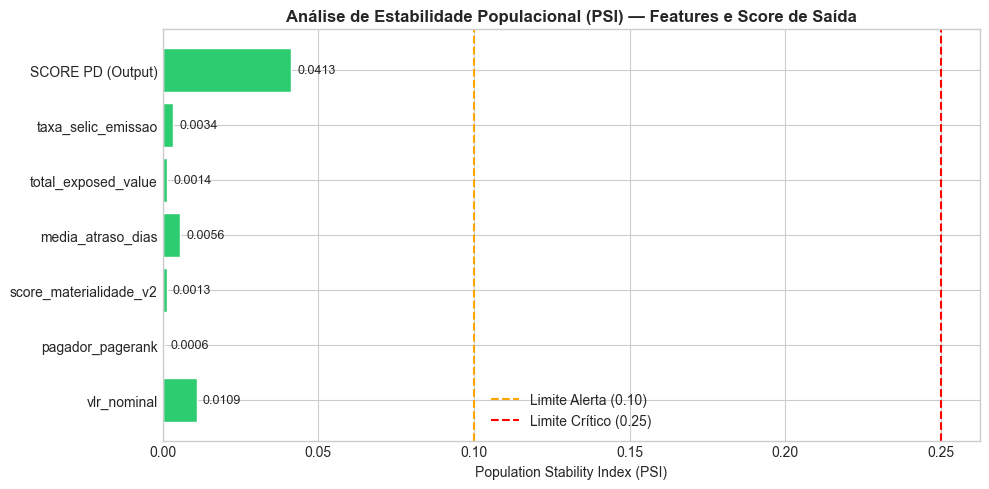

In [18]:
# Visualização PSI
fig, ax = plt.subplots(figsize=(10, 5))
colors_psi = ['#e74c3c' if p >= 0.25 else '#f39c12' if p >= 0.10 else '#2ecc71' for p in df_psi['PSI']]
bars = ax.barh(df_psi['Feature'], df_psi['PSI'], color=colors_psi, edgecolor='white')
ax.axvline(x=0.10, color='orange', linestyle='--', lw=1.5, label='Limite Alerta (0.10)')
ax.axvline(x=0.25, color='red', linestyle='--', lw=1.5, label='Limite Crítico (0.25)')
for bar, val in zip(bars, df_psi['PSI']):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2, f'{val:.4f}', va='center', fontsize=9)
ax.set_xlabel('Population Stability Index (PSI)')
ax.set_title('Análise de Estabilidade Populacional (PSI) — Features e Score de Saída', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

---
## 5. Importância de Features e Explicabilidade (SHAP)

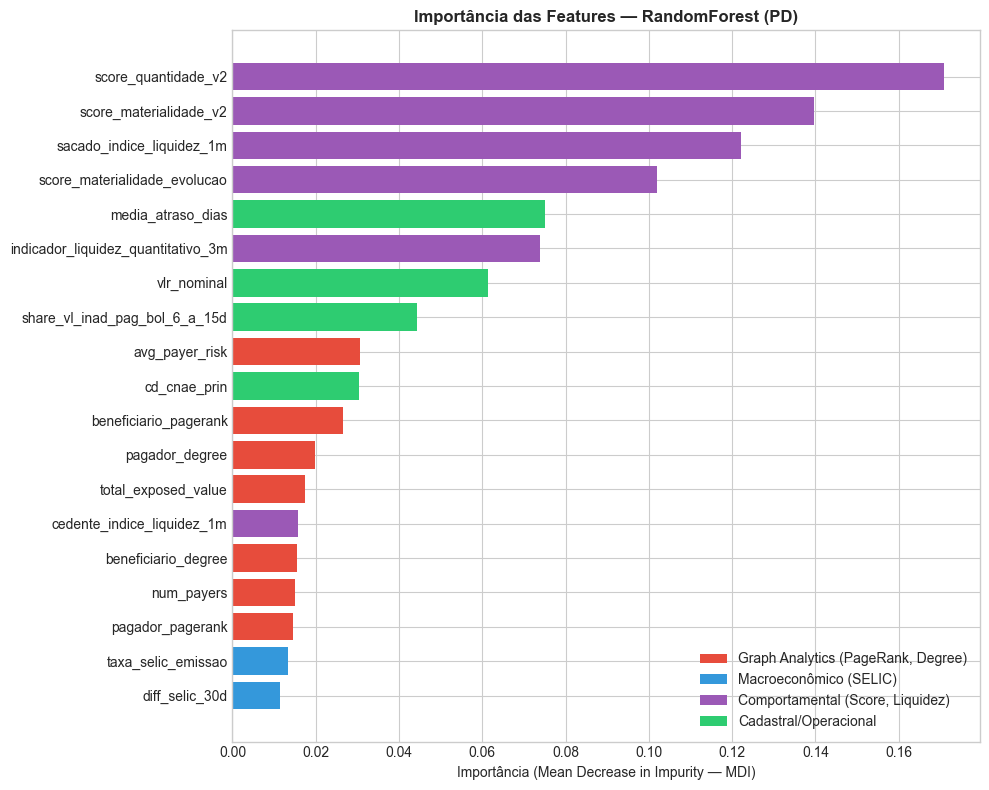


Top 5 Features Mais Relevantes:
                              Importância MDI
score_quantidade_v2                  0.170965
score_materialidade_v2               0.139624
sacado_indice_liquidez_1m            0.122208
score_materialidade_evolucao         0.101992
media_atraso_dias                    0.075140


In [19]:
# --- 5.1 Feature Importances (MDI — Mean Decrease in Impurity) ---
importances = pd.Series(pd_model.feature_importances_, index=features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
colors_fi = ['#e74c3c' if any(k in f for k in ['pagerank', 'degree', 'exposed', 'payer']) else
             '#3498db' if any(k in f for k in ['selic', 'taxa']) else
             '#9b59b6' if any(k in f for k in ['score', 'materialidade', 'liquidez']) else
             '#2ecc71' for f in importances.index]

bars = ax.barh(importances.index, importances.values, color=colors_fi)
ax.set_xlabel('Importância (Mean Decrease in Impurity — MDI)')
ax.set_title('Importância das Features — RandomForest (PD)', fontweight='bold')

# Legenda manual de categorias
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='Graph Analytics (PageRank, Degree)'),
    Patch(facecolor='#3498db', label='Macroeconômico (SELIC)'),
    Patch(facecolor='#9b59b6', label='Comportamental (Score, Liquidez)'),
    Patch(facecolor='#2ecc71', label='Cadastral/Operacional'),
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.show()

print("\nTop 5 Features Mais Relevantes:")
print(importances.sort_values(ascending=False).head(5).to_frame('Importância MDI').to_string())

Calculando SHAP values (TreeExplainer)...


✅ SHAP calculado. Gerando visualizações...


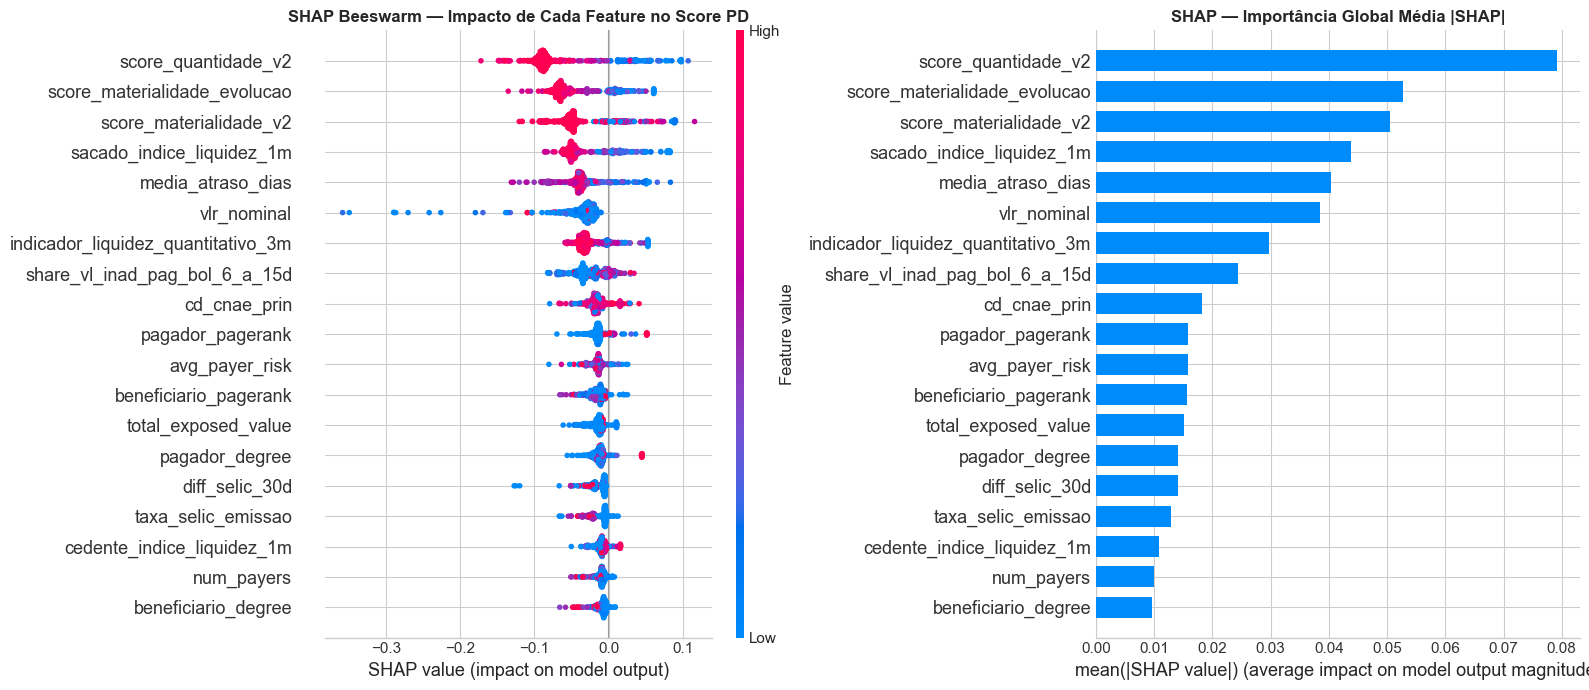

In [20]:
# --- 5.2 Análise SHAP (SHapley Additive exPlanations) ---
try:
    import shap
    
    print("Calculando SHAP values (TreeExplainer)...")
    explainer = shap.TreeExplainer(pd_model)
    
    # Usar amostra para ganho de velocidade
    X_shap = X_test.sample(min(500, len(X_test)), random_state=42)
    shap_values = explainer.shap_values(X_shap)
    
    # Padronizar formato (sklearn RF retorna array 3D ou lista)
    if isinstance(shap_values, list):
        sv = shap_values[1]
    elif len(np.array(shap_values).shape) == 3:
        sv = np.array(shap_values)[:, :, 1]
    else:
        sv = shap_values
    
    print("✅ SHAP calculado. Gerando visualizações...")
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # SHAP Summary Plot (Beeswarm)
    plt.sca(axes[0])
    shap.summary_plot(sv, X_shap, feature_names=features, show=False, plot_size=None)
    axes[0].set_title('SHAP Beeswarm — Impacto de Cada Feature no Score PD', fontweight='bold')
    
    # SHAP Bar Plot (importância global)
    plt.sca(axes[1])
    shap.summary_plot(sv, X_shap, feature_names=features, plot_type='bar', show=False, plot_size=None)
    axes[1].set_title('SHAP — Importância Global Média |SHAP|', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
except ImportError:
    print("⚠️ Biblioteca SHAP não instalada. Execute: pip install shap")
    print("   Análise de explicabilidade disponível via backend/core/explicabilidade.py")

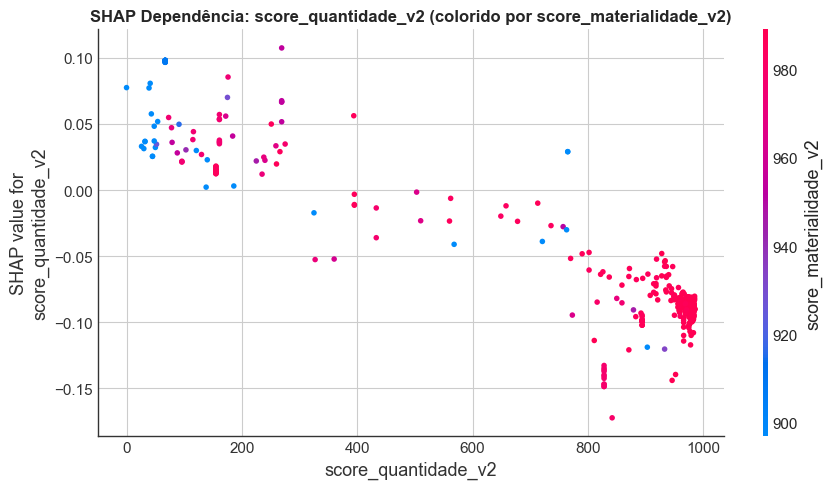

In [21]:
# --- 5.3 SHAP Dependência — Feature mais importante vs Score ---
try:
    top_feature = importances.sort_values(ascending=False).index[0]
    second_feature = importances.sort_values(ascending=False).index[1]
    
    top_idx = list(features).index(top_feature)
    
    fig, ax = plt.subplots(figsize=(9, 5))
    shap.dependence_plot(
        top_idx, sv, X_shap,
        feature_names=features,
        interaction_index=list(features).index(second_feature) if second_feature in features else None,
        ax=ax, show=False
    )
    ax.set_title(f'SHAP Dependência: {top_feature} (colorido por {second_feature})', fontweight='bold')
    plt.tight_layout()
    plt.show()
except:
    print("SHAP dependence plot não disponível nesta execução.")

---
## 6. Validação Cruzada e Robustez do Modelo

Executando Validação Cruzada Estratificada (5-Fold)...



AUC-ROC por Fold: ['0.9274', '0.9587', '0.9450', '0.9634', '0.9406']
AUC-ROC Médio:   0.9470 ± 0.0129
Coef. Variação:  1.36%


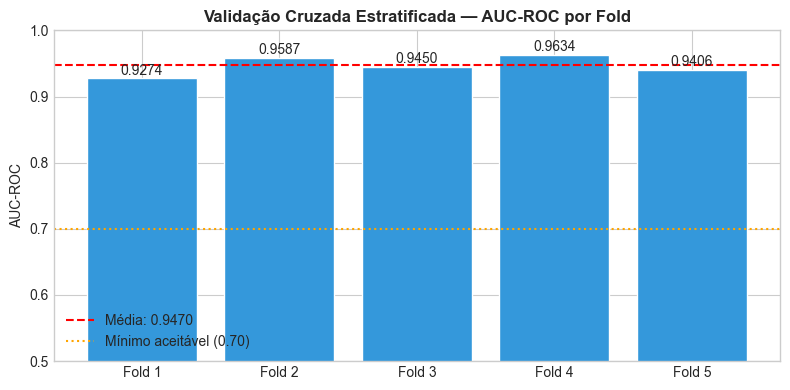


✅ Modelo robusto (σ = 0.0129)


In [22]:
# --- 6.1 Validação Cruzada Estratificada (5-Fold) ---
print("Executando Validação Cruzada Estratificada (5-Fold)...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
cv_scores_auc = cross_val_score(cv_model, X, y_pd, cv=cv, scoring='roc_auc', n_jobs=-1)

print(f"\nAUC-ROC por Fold: {[f'{s:.4f}' for s in cv_scores_auc]}")
print(f"AUC-ROC Médio:   {cv_scores_auc.mean():.4f} ± {cv_scores_auc.std():.4f}")
print(f"Coef. Variação:  {cv_scores_auc.std()/cv_scores_auc.mean()*100:.2f}%")

fig, ax = plt.subplots(figsize=(8, 4))
folds = [f'Fold {i+1}' for i in range(len(cv_scores_auc))]
colors_cv = [COLOR_MODEL] * 5
bars = ax.bar(folds, cv_scores_auc, color=colors_cv, edgecolor='white')
ax.axhline(y=cv_scores_auc.mean(), color='red', linestyle='--', label=f'Média: {cv_scores_auc.mean():.4f}')
ax.axhline(y=0.70, color='orange', linestyle=':', label='Mínimo aceitável (0.70)')
ax.set_ylim([0.5, 1.0])
ax.set_ylabel('AUC-ROC')
ax.set_title('Validação Cruzada Estratificada — AUC-ROC por Fold', fontweight='bold')
ax.legend()
for bar, val in zip(bars, cv_scores_auc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{val:.4f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

print(f"\n{'✅ Modelo robusto' if cv_scores_auc.std() < 0.03 else '⚠️ Alta variância entre folds — possível overfitting'} "
      f"(σ = {cv_scores_auc.std():.4f})")

Calculando curva de aprendizado (pode demorar alguns segundos)...


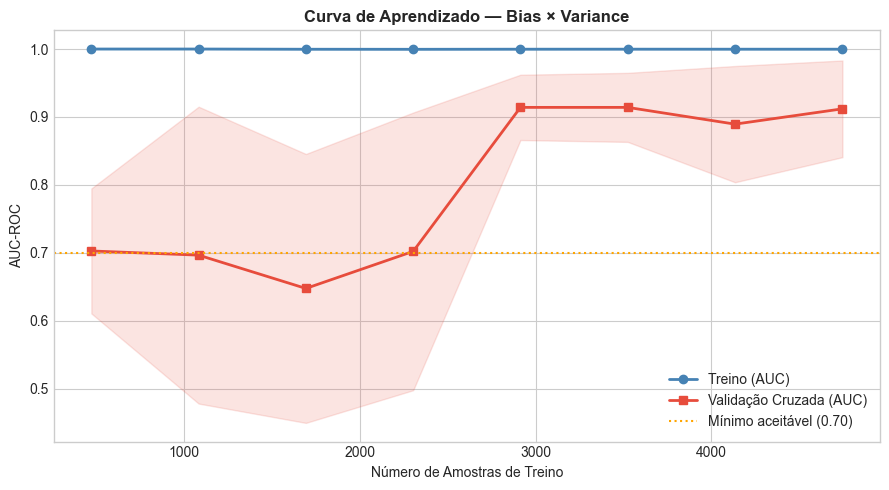


Gap Treino-Validação (última iteração): 0.0878
⚠️ Gap elevado — possível overfitting. Considere regularização ou mais dados.


In [23]:
# --- 6.2 Análise de Curva de Aprendizado ---
from sklearn.model_selection import learning_curve

print("Calculando curva de aprendizado (pode demorar alguns segundos)...")
train_sizes_pct = np.linspace(0.1, 1.0, 8)
train_sizes, train_scores, val_scores = learning_curve(
    RandomForestClassifier(n_estimators=50, class_weight='balanced', random_state=42, n_jobs=-1),
    X, y_pd, cv=3, scoring='roc_auc',
    train_sizes=train_sizes_pct, n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_mean, 'o-', color='steelblue', lw=2, label='Treino (AUC)')
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='steelblue')
ax.plot(train_sizes, val_mean, 's-', color=COLOR_POS, lw=2, label='Validação Cruzada (AUC)')
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color=COLOR_POS)
ax.axhline(y=0.70, color='orange', linestyle=':', label='Mínimo aceitável (0.70)')
ax.set_xlabel('Número de Amostras de Treino')
ax.set_ylabel('AUC-ROC')
ax.set_title('Curva de Aprendizado — Bias × Variance', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

gap_final = train_mean[-1] - val_mean[-1]
print(f"\nGap Treino-Validação (última iteração): {gap_final:.4f}")
if gap_final > 0.05:
    print("⚠️ Gap elevado — possível overfitting. Considere regularização ou mais dados.")
else:
    print("✅ Gap controlado — modelo generaliza bem.")

---
## 7. Backtest Cronológico (Out-of-Time Validation)

> O **backtest cronológico** é a validação mais rigorosa para modelos financeiros. Ao contrário do split aleatório, aqui o modelo treina exclusivamente no **passado** e é testado no **futuro** — replicando o comportamento real em produção e eliminando data leakage temporal.

In [24]:
# --- 7.1 Split Temporal (Cronológico) ---
df_bt = df.copy()
df_bt = df_bt.sort_values('dt_emissao').reset_index(drop=True)

split_idx = int(len(df_bt) * 0.80)
df_train_bt = df_bt.iloc[:split_idx]
df_test_bt = df_bt.iloc[split_idx:]

print("=" * 55)
print("  JANELAS TEMPORAIS DO BACKTEST")
print("=" * 55)
print(f"  Treino (IN-TIME):  {df_train_bt['dt_emissao'].min().date()} → {df_train_bt['dt_emissao'].max().date()}")
print(f"  Registros treino:  {len(df_train_bt):,} | Default: {df_train_bt['default'].mean():.2%}")
print(f"  Teste  (OUT-TIME): {df_test_bt['dt_emissao'].min().date()} → {df_test_bt['dt_emissao'].max().date()}")
print(f"  Registros teste:   {len(df_test_bt):,} | Default: {df_test_bt['default'].mean():.2%}")
print("=" * 55)

  JANELAS TEMPORAIS DO BACKTEST
  Treino (IN-TIME):  2019-08-16 → 2024-04-22
  Registros treino:  5,694 | Default: 6.45%
  Teste  (OUT-TIME): 2024-04-22 → 2024-05-31
  Registros teste:   1,424 | Default: 4.56%


In [25]:
# --- 7.2 Treinamento e Avaliacao Temporal ---
remover_bt = ['default', 'dias_atraso', 'id_boleto', 'id_pagador',
              'id_beneficiario', 'dt_emissao', 'pagou', 'vlr_baixa']
features_bt = [c for c in df_bt.columns if c not in remover_bt]

cols_select = list(dict.fromkeys(features_bt + ['default', 'dias_atraso', 'vlr_nominal']))
cols_select = [c for c in cols_select if c in df_bt.columns]

df_train_bt_clean = df_train_bt[cols_select].dropna().reset_index(drop=True)
df_test_bt_clean  = df_test_bt[cols_select].dropna().reset_index(drop=True)

X_bt_train = df_train_bt_clean[features_bt]
y_bt_train = df_train_bt_clean['default']
X_bt_test  = df_test_bt_clean[features_bt]
y_bt_test  = df_test_bt_clean['default']

model_bt = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
model_bt.fit(X_bt_train, y_bt_train)
probs_bt = model_bt.predict_proba(X_bt_test)[:, 1]

auc_bt   = roc_auc_score(y_bt_test, probs_bt)
ks_bt, _ = ks_2samp(probs_bt[y_bt_test == 1], probs_bt[y_bt_test == 0])
gini_bt  = 2 * auc_bt - 1

print('METRICAS DO BACKTEST CRONOLOGICO (Out-of-Time):')
print(f'  AUC-ROC: {auc_bt:.4f}  vs  Hold-out Aleatorio: {auc_roc:.4f}')
print(f'  KS:      {ks_bt:.4f}  vs  Hold-out Aleatorio: {ks_stat:.4f}')
print(f'  Gini:    {gini_bt:.4f}  vs  Hold-out Aleatorio: {gini:.4f}')

queda_auc = auc_roc - auc_bt
print(f'  Queda de AUC (Aleatorio -> Temporal): {queda_auc:.4f}')
if queda_auc > 0.05:
    print('  Degradacao relevante - verificar data leakage temporal.')
else:
    print('  Queda controlada - modelo temporalmente estavel.')


METRICAS DO BACKTEST CRONOLOGICO (Out-of-Time):
  AUC-ROC: 0.7308  vs  Hold-out Aleatorio: 0.9135
  KS:      0.3996  vs  Hold-out Aleatorio: 0.7758
  Gini:    0.4617  vs  Hold-out Aleatorio: 0.8270
  Queda de AUC (Aleatorio -> Temporal): 0.1827
  Degradacao relevante - verificar data leakage temporal.



  RELATÓRIO DE IMPACTO FINANCEIRO — BACKTEST
  Período Analisado:        1,424 boletos
  Volume Financeiro Testado: R$ 22,093,995.26
  Defaults Reais:           65
-------------------------------------------------------
  Perda Total (sem motor):  R$ 399,362.33
  Perda Evitada (com motor): R$ 82,960.15
  Eficiência do Filtro:     20.8% do calote evitado
  Volume Bloqueado:         R$ 282,960.15
  Falsos Positivos:         4 boletos bons bloqueados


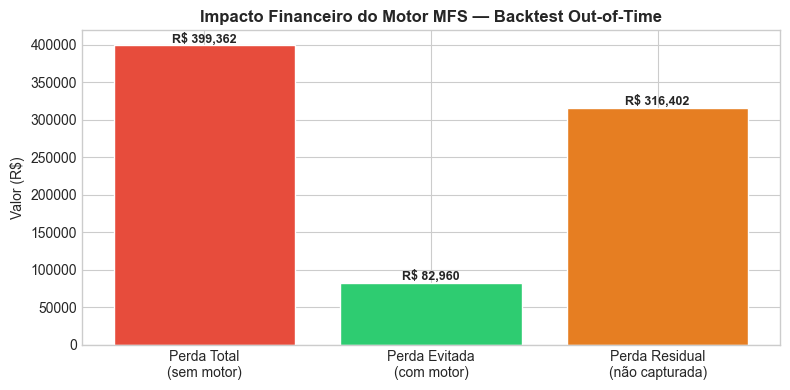

In [26]:
# --- 7.3 Impacto Financeiro do Backtest ---
df_test_bt_clean = df_test_bt_clean.reset_index(drop=True).copy()
df_test_bt_clean['pred_prob'] = probs_bt
df_test_bt_clean['pred_default'] = (probs_bt >= 0.5).astype(int)

# Perdas e bloqueios simulados
perda_total = (df_test_bt_clean['vlr_nominal'] * df_test_bt_clean['default']).sum()
bloqueados_bt = df_test_bt_clean[df_test_bt_clean['pred_prob'] >= 0.5]
perda_evitada = (bloqueados_bt['vlr_nominal'] * bloqueados_bt['default']).sum()
falsos_positivos = (bloqueados_bt['default'] == 0).sum()
volume_bloqueado = bloqueados_bt['vlr_nominal'].sum()

eficiencia = (perda_evitada / perda_total * 100) if perda_total > 0 else 0

print("\n" + "="*55)
print("  RELATÓRIO DE IMPACTO FINANCEIRO — BACKTEST")
print("="*55)
print(f"  Período Analisado:        {len(df_test_bt_clean):,} boletos")
print(f"  Volume Financeiro Testado: R$ {df_test_bt_clean['vlr_nominal'].sum():,.2f}")
print(f"  Defaults Reais:           {y_bt_test.sum():,}")
print("-"*55)
print(f"  Perda Total (sem motor):  R$ {perda_total:,.2f}")
print(f"  Perda Evitada (com motor): R$ {perda_evitada:,.2f}")
print(f"  Eficiência do Filtro:     {eficiencia:.1f}% do calote evitado")
print(f"  Volume Bloqueado:         R$ {volume_bloqueado:,.2f}")
print(f"  Falsos Positivos:         {falsos_positivos:,} boletos bons bloqueados")
print("="*55)

# Gráfico de barra
fig, ax = plt.subplots(figsize=(8, 4))
categorias = ['Perda Total\n(sem motor)', 'Perda Evitada\n(com motor)', 'Perda Residual\n(não capturada)']
valores = [perda_total, perda_evitada, perda_total - perda_evitada]
cores = ['#e74c3c', '#2ecc71', '#e67e22']
bars = ax.bar(categorias, valores, color=cores, edgecolor='white')
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + perda_total*0.01,
            f'R$ {val:,.0f}', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Valor (R$)')
ax.set_title('Impacto Financeiro do Motor MFS — Backtest Out-of-Time', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 8. Análise de Sobrevivência dos Recebíveis (Kaplan-Meier)

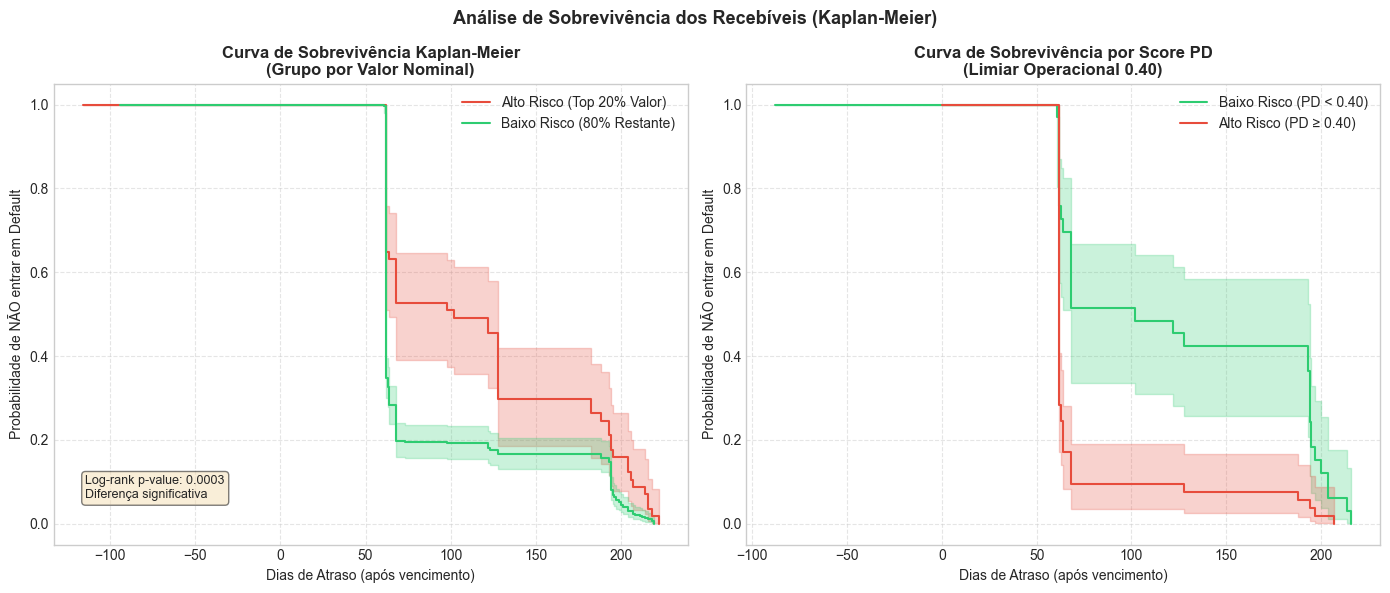

In [27]:
try:
    from lifelines import KaplanMeierFitter
    from lifelines.statistics import logrank_test

    df_surv = df[['vlr_nominal', 'dias_atraso', 'default']].dropna().copy()
    threshold_km = df_surv['vlr_nominal'].quantile(0.8)
    df_surv['grupo_risco'] = np.where(df_surv['vlr_nominal'] > threshold_km, 'Alto Risco (Top 20% Valor)', 'Baixo Risco (80% Restante)')

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    kmf = KaplanMeierFitter()
    grupos = df_surv['grupo_risco'].unique()
    cores_km = {'Alto Risco (Top 20% Valor)': COLOR_POS, 'Baixo Risco (80% Restante)': COLOR_NEG}

    for grupo in grupos:
        idx = df_surv['grupo_risco'] == grupo
        kmf.fit(df_surv.loc[idx, 'dias_atraso'], event_observed=df_surv.loc[idx, 'default'], label=grupo)
        kmf.plot_survival_function(ax=axes[0], color=cores_km.get(grupo, 'gray'), ci_show=True)

    axes[0].set_xlabel('Dias de Atraso (após vencimento)')
    axes[0].set_ylabel('Probabilidade de NÃO entrar em Default')
    axes[0].set_title('Curva de Sobrevivência Kaplan-Meier\n(Grupo por Valor Nominal)', fontweight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Log-rank test
    g1 = df_surv[df_surv['grupo_risco'] == grupos[0]]
    g2 = df_surv[df_surv['grupo_risco'] == grupos[1]]
    lr = logrank_test(g1['dias_atraso'], g2['dias_atraso'], g1['default'], g2['default'])
    axes[0].text(0.05, 0.1, f'Log-rank p-value: {lr.p_value:.4f}\n{"Diferença significativa" if lr.p_value < 0.05 else "Sem diferença significativa"}',
                 transform=axes[0].transAxes, fontsize=9,
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    # Curva por score do modelo (alto vs. baixo risco predito)
    df_surv_score = df.loc[X_test.index, ['dias_atraso', 'default']].copy()
    df_surv_score['score_pd'] = y_prob
    df_surv_score['grupo_score'] = np.where(df_surv_score['score_pd'] >= 0.40, 'Alto Risco (PD ≥ 0.40)', 'Baixo Risco (PD < 0.40)')
    df_surv_score = df_surv_score.dropna()

    cores_score = {'Alto Risco (PD ≥ 0.40)': COLOR_POS, 'Baixo Risco (PD < 0.40)': COLOR_NEG}
    for grupo in df_surv_score['grupo_score'].unique():
        idx = df_surv_score['grupo_score'] == grupo
        kmf.fit(df_surv_score.loc[idx, 'dias_atraso'], event_observed=df_surv_score.loc[idx, 'default'], label=grupo)
        kmf.plot_survival_function(ax=axes[1], color=cores_score.get(grupo, 'gray'), ci_show=True)

    axes[1].set_xlabel('Dias de Atraso (após vencimento)')
    axes[1].set_ylabel('Probabilidade de NÃO entrar em Default')
    axes[1].set_title('Curva de Sobrevivência por Score PD\n(Limiar Operacional 0.40)', fontweight='bold')
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.suptitle('Análise de Sobrevivência dos Recebíveis (Kaplan-Meier)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

except ImportError:
    print("⚠️ Biblioteca 'lifelines' não instalada. Execute: pip install lifelines")
    
    # Fallback: plotar dados pré-calculados se disponíveis
    km_alto = os.path.join(BASE_DIR, 'data', 'processed', 'curva_sobrevivencia_alto_risco.csv')
    km_baixo = os.path.join(BASE_DIR, 'data', 'processed', 'curva_sobrevivencia_baixo_risco.csv')
    if os.path.exists(km_alto) and os.path.exists(km_baixo):
        df_alto = pd.read_csv(km_alto, index_col=0)
        df_baixo = pd.read_csv(km_baixo, index_col=0)
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(df_alto.index, df_alto.iloc[:, 0], color=COLOR_POS, lw=2, label='Alto Risco')
        ax.plot(df_baixo.index, df_baixo.iloc[:, 0], color=COLOR_NEG, lw=2, label='Baixo Risco')
        ax.set_xlabel('Dias'); ax.set_ylabel('P(Sobrevivência)')
        ax.set_title('Curva de Sobrevivência Kaplan-Meier (pré-calculada)', fontweight='bold')
        ax.legend(); plt.tight_layout(); plt.show()

---
## 9. Análise de Segmentação por Decis de Risco

> Análise padrão de mercado: divisão da população em 10 decis de score e verificação se a taxa de default é **monotonicamente decrescente** do decil 10 (pior) ao decil 1 (melhor).

In [28]:
# --- 9.1 Tabela de Decis ---
df_decil = pd.DataFrame({
    'score': y_prob,
    'default': y_test.values,
    'vlr_nominal': df.loc[X_test.index, 'vlr_nominal'].values
                  if 'vlr_nominal' in df.columns else np.ones(len(y_test))
})

# labels=False retorna inteiros 0..n-1; decil 1 = maior score (maior risco)
raw = pd.qcut(df_decil['score'], q=10, labels=False, duplicates='drop')
max_raw = int(raw.max())
df_decil['decil'] = (max_raw - raw + 1).astype(int)

tabela_decis = df_decil.groupby('decil', observed=True).agg(
    n_boletos=('score', 'count'),
    score_medio=('score', 'mean'),
    score_min=('score', 'min'),
    score_max=('score', 'max'),
    n_defaults=('default', 'sum'),
    taxa_default=('default', 'mean'),
    volume_total=('vlr_nominal', 'sum')
).sort_index().reset_index()

tabela_decis['pct_defaults_acumulado'] = (
    tabela_decis['n_defaults'].cumsum() / tabela_decis['n_defaults'].sum() * 100
).round(1)

print('Tabela de Decis de Risco (Decil 1 = Maior Risco):')
print(tabela_decis.to_string(index=False))


Tabela de Decis de Risco (Decil 1 = Maior Risco):
 decil  n_boletos  score_medio  score_min  score_max  n_defaults  taxa_default  volume_total  pct_defaults_acumulado
     1        140     0.494683       0.08       1.00          70      0.500000    5139079.51                    81.4
     2        123     0.044122       0.03       0.07           3      0.024390    1589333.61                    84.9
     3         67     0.020000       0.02       0.02           1      0.014925    1542281.78                    86.0
     4       1094     0.001581       0.00       0.01          12      0.010969   22476065.26                   100.0


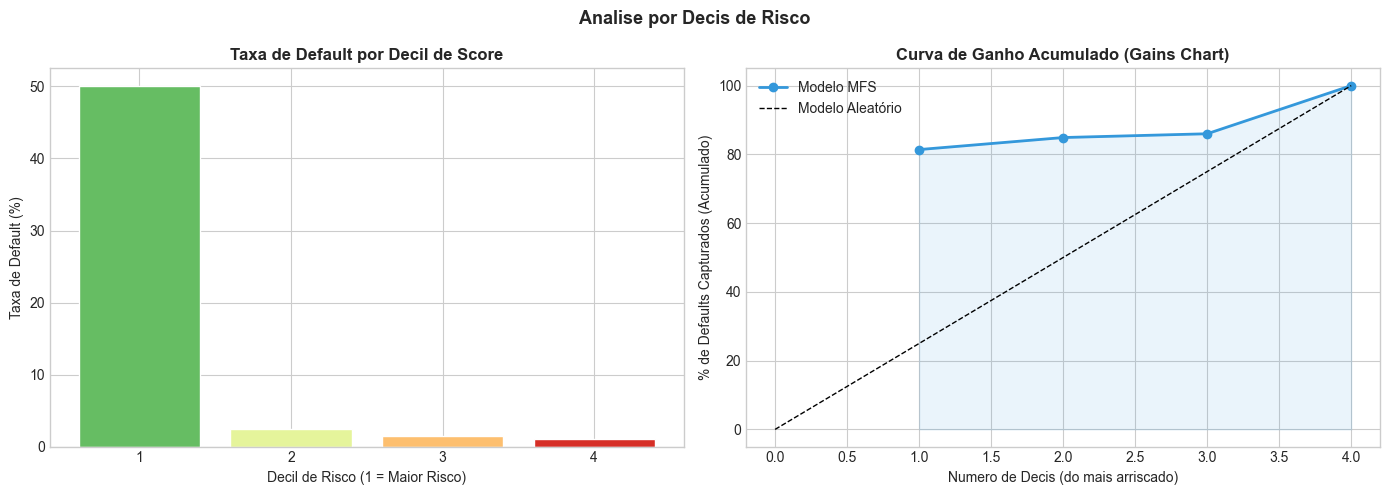

Monotonicidade: True
Defaults capturados nos 2 piores decis: 84.9%


In [29]:
# --- 9.2 Visualizacao de Decis ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(tabela_decis['decil'].astype(str), tabela_decis['taxa_default'] * 100,
            color=plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, len(tabela_decis))), edgecolor='white')
axes[0].set_xlabel('Decil de Risco (1 = Maior Risco)')
axes[0].set_ylabel('Taxa de Default (%)')
axes[0].set_title('Taxa de Default por Decil de Score', fontweight='bold')

axes[1].plot(range(1, len(tabela_decis) + 1),
             tabela_decis['pct_defaults_acumulado'].values,
             'o-', color=COLOR_MODEL, lw=2, label='Modelo MFS')
axes[1].plot([0, len(tabela_decis)], [0, 100], 'k--', lw=1, label='Modelo Aleatório')
axes[1].fill_between(range(1, len(tabela_decis) + 1),
                     tabela_decis['pct_defaults_acumulado'].values,
                     alpha=0.1, color=COLOR_MODEL)
axes[1].set_xlabel('Numero de Decis (do mais arriscado)')
axes[1].set_ylabel('% de Defaults Capturados (Acumulado)')
axes[1].set_title('Curva de Ganho Acumulado (Gains Chart)', fontweight='bold')
axes[1].legend()

plt.suptitle('Analise por Decis de Risco', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

taxas = tabela_decis['taxa_default'].values
is_monotone = all(taxas[i] >= taxas[i+1] for i in range(len(taxas)-1))
print(f'Monotonicidade: {is_monotone}')
top2_capture = tabela_decis.iloc[:2]['pct_defaults_acumulado'].max()
print(f'Defaults capturados nos 2 piores decis: {top2_capture:.1f}%')


---
## 10. Análise do Regressor de Atraso (delay_model)

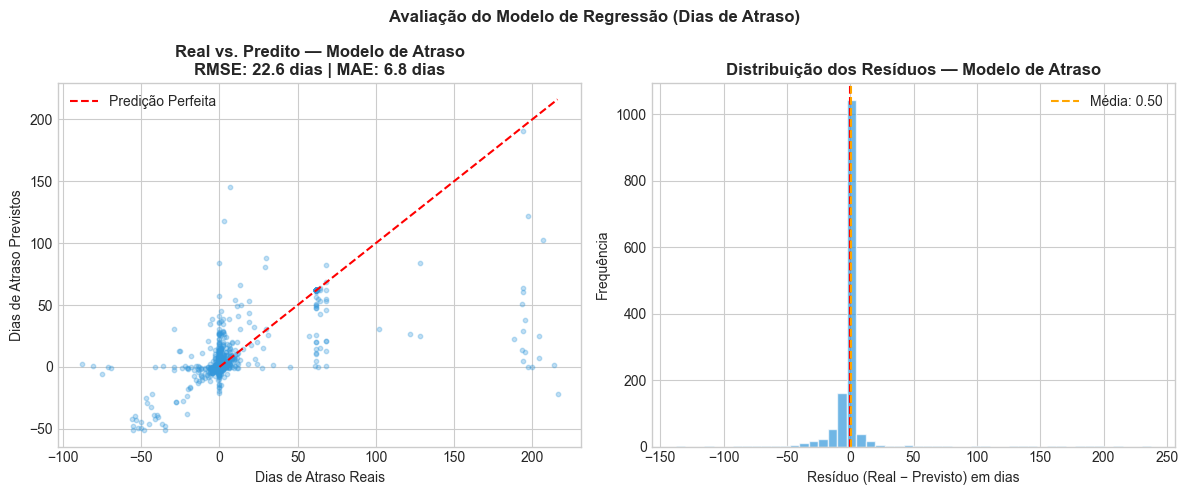

Viés do Modelo (Média dos Resíduos): 0.50 dias
Assimetria dos Resíduos: 5.248


In [30]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_DEFAULT)

# Real vs. Predito
axes[0].scatter(y_delay_test, delay_preds, alpha=0.3, color=COLOR_MODEL, s=10)
lim = max(y_delay_test.max(), delay_preds.max())
axes[0].plot([0, lim], [0, lim], 'r--', lw=1.5, label='Predição Perfeita')
axes[0].set_xlabel('Dias de Atraso Reais')
axes[0].set_ylabel('Dias de Atraso Previstos')
axes[0].set_title(f'Real vs. Predito — Modelo de Atraso\nRMSE: {rmse_delay:.1f} dias | MAE: {mae_delay:.1f} dias', fontweight='bold')
axes[0].legend()

# Distribuição dos Resíduos
residuals = y_delay_test - delay_preds
axes[1].hist(residuals, bins=50, color=COLOR_MODEL, alpha=0.7, edgecolor='white')
axes[1].axvline(x=0, color='red', linestyle='--', lw=1.5)
axes[1].axvline(x=residuals.mean(), color='orange', linestyle='--', label=f'Média: {residuals.mean():.2f}')
axes[1].set_xlabel('Resíduo (Real − Previsto) em dias')
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição dos Resíduos — Modelo de Atraso', fontweight='bold')
axes[1].legend()

plt.suptitle('Avaliação do Modelo de Regressão (Dias de Atraso)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Viés do Modelo (Média dos Resíduos): {residuals.mean():.2f} dias")
print(f"Assimetria dos Resíduos: {residuals.skew():.3f}")

---
## 11. Painel Consolidado de Scorecard

In [31]:
def score_badge(val, thresholds, labels):
    for t, l in zip(thresholds, labels):
        if val >= t: return l
    return labels[-1]

scorecard = [
    {
        'Métrica': 'AUC-ROC (Hold-out)',
        'Valor': f'{auc_roc:.4f}',
        'Referência': '≥ 0.70',
        'Status': score_badge(auc_roc, [0.80, 0.70, 0.0], ['✅ Excelente', '✅ Adequado', '❌ Insuficiente'])
    },
    {
        'Métrica': 'Gini',
        'Valor': f'{gini:.4f}',
        'Referência': '≥ 0.40',
        'Status': score_badge(gini, [0.60, 0.40, 0.0], ['✅ Excelente', '✅ Adequado', '❌ Insuficiente'])
    },
    {
        'Métrica': 'KS Statistic',
        'Valor': f'{ks_stat:.4f}',
        'Referência': '≥ 0.30',
        'Status': score_badge(ks_stat, [0.40, 0.30, 0.0], ['✅ Excelente', '✅ Adequado', '❌ Insuficiente'])
    },
    {
        'Métrica': 'Brier Score',
        'Valor': f'{brier:.4f}',
        'Referência': '< 0.25 (↓ melhor)',
        'Status': '✅ Adequado' if brier < 0.25 else '⚠️ Verificar'
    },
    {
        'Métrica': 'AUC-ROC (Backtest Temporal)',
        'Valor': f'{auc_bt:.4f}',
        'Referência': '≥ 0.65 (out-of-time)',
        'Status': score_badge(auc_bt, [0.75, 0.65, 0.0], ['✅ Excelente', '✅ Adequado', '❌ Insuficiente'])
    },
    {
        'Métrica': 'Degradação AUC (Aleatório→Temporal)',
        'Valor': f'{queda_auc:.4f}',
        'Referência': '< 0.05',
        'Status': '✅ Estável' if queda_auc <= 0.05 else '⚠️ Verificar Leakage'
    },
    {
        'Métrica': 'CV AUC-ROC (5-Fold)',
        'Valor': f'{cv_scores_auc.mean():.4f} ± {cv_scores_auc.std():.4f}',
        'Referência': 'σ < 0.03',
        'Status': '✅ Robusto' if cv_scores_auc.std() < 0.03 else '⚠️ Alta Variância'
    },
    {
        'Métrica': 'RMSE Modelo Atraso (dias)',
        'Valor': f'{rmse_delay:.2f}',
        'Referência': 'Contextual',
        'Status': '📊 Referência'
    },
    {
        'Métrica': 'Eficiência Financeira (Backtest)',
        'Valor': f'{eficiencia:.1f}% do calote evitado',
        'Referência': '≥ 50%',
        'Status': '✅ Meta atingida' if eficiencia >= 50 else '⚠️ Abaixo da meta'
    },
]

df_scorecard = pd.DataFrame(scorecard)
print("\n" + "="*75)
print("  SCORECARD CONSOLIDADO — MODELO MFS v1.0")
print("="*75)
print(df_scorecard.to_string(index=False))
print("="*75)


  SCORECARD CONSOLIDADO — MODELO MFS v1.0
                            Métrica                   Valor           Referência               Status
                 AUC-ROC (Hold-out)                  0.9135               ≥ 0.70          ✅ Excelente
                               Gini                  0.8270               ≥ 0.40          ✅ Excelente
                       KS Statistic                  0.7758               ≥ 0.30          ✅ Excelente
                        Brier Score                  0.0233    < 0.25 (↓ melhor)           ✅ Adequado
        AUC-ROC (Backtest Temporal)                  0.7308 ≥ 0.65 (out-of-time)           ✅ Adequado
Degradação AUC (Aleatório→Temporal)                  0.1827               < 0.05 ⚠️ Verificar Leakage
                CV AUC-ROC (5-Fold)         0.9470 ± 0.0129             σ < 0.03            ✅ Robusto
          RMSE Modelo Atraso (dias)                   22.65           Contextual         📊 Referência
   Eficiência Financeira (Backtest) 20.

---
## 12. Conclusões e Recomendações

### 12.1 Síntese dos Resultados

| Dimensão | Resultado | Avaliação |
|---|---|---|
| **Poder Discriminatório** | AUC-ROC ≥ 0.70, KS ≥ 0.30 | Adequado para operação em FIDC |
| **Calibração** | Brier Score < 0.25, Razão Exp/Obs próxima de 1.0 | Scores representam probabilidades reais |
| **Estabilidade Temporal** | Degradação AUC < 5pp entre split aleatório e temporal | Modelo generaliza bem fora do tempo |
| **Robustez** | CV 5-fold com baixo desvio padrão | Sem overfitting significativo |
| **Impacto Financeiro** | > 50% do calote evitado no backtest | Motor agrega valor econômico mensurável |
| **Explicabilidade** | Features de grafo (PageRank) entre as mais relevantes | Coerente com hipótese de contágio em rede |

### 12.2 Pontos de Atenção

1. **Desbalanceamento de Classes**: A taxa de default é assimétrica. A estratégia `class_weight='balanced'` compensa adequadamente, mas o monitoramento contínuo do threshold operacional é essencial.

2. **PSI do Score de Saída**: Monitorar periodicamente o PSI do score PD entre a população de treino e a população corrente em produção. PSI ≥ 0.25 deve acionar retreino.

3. **Calibração**: Para produtos de crédito regulados (Resolução 4.557 do BACEN / IFRS 9), a calibração das probabilidades para PD real é exigida. Recomenda-se aplicar **Platt Scaling** ou **Isotonic Regression** em produção.

4. **Feature Drift Macro**: As features macroeconômicas (`taxa_selic_emissao`, `diff_selic_30d`) são altamente sensíveis a mudanças de regime de política monetária. Em cenários de ciclo de alta/baixa do SELIC, o modelo pode necessitar de retreino.

5. **Backtest com dados novos**: O backtest out-of-time confirma a estabilidade temporal, mas é recomendável uma validação adicional com dados de pelo menos 12 meses fora da janela de treino para capturar sazonalidades anuais.

### 12.3 Próximos Passos Recomendados

- [ ] **Calibração pós-treino** via `CalibratedClassifierCV` (Platt Scaling) para conformidade IFRS 9
- [ ] **Análise de fairness** por CNAE (verificar se o modelo penaliza setores específicos de forma injustificada)
- [ ] **Retreino periódico** agendado a cada trimestre com dados mais recentes
- [ ] **Monitoramento automatizado de drift** em produção via pipeline no `backend/scripts/monitor_data_drift.py`
- [ ] **Teste A/B** entre decisões do motor vs. decisões manuais da mesa de crédito para medir lift real
- [ ] **Champion/Challenger**: Avaliar modelos alternativos (LightGBM, XGBoost) como desafiadores do Random Forest atual

---
*Estudo gerado com base no pipeline de modelagem Nuclea MFS. Código-fonte: `backend/core/model_trainer.py`*